<a href="https://colab.research.google.com/github/2004sreedevip/ML-Lab-/blob/main/AML_Assignment(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Qn-1a

import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

data = load_diabetes()
X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=1.0)
}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    print("\n", name)
    print("Mean Squared Error:", round(mse, 2))
    print("R2 Score:", round(r2, 4))


 Linear Regression
Mean Squared Error: 2900.19
R2 Score: 0.4526

 Ridge Regression
Mean Squared Error: 2892.01
R2 Score: 0.4541

 Lasso Regression
Mean Squared Error: 2824.57
R2 Score: 0.4669



Model: Gini Impurity
Accuracy: 93.33 %
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



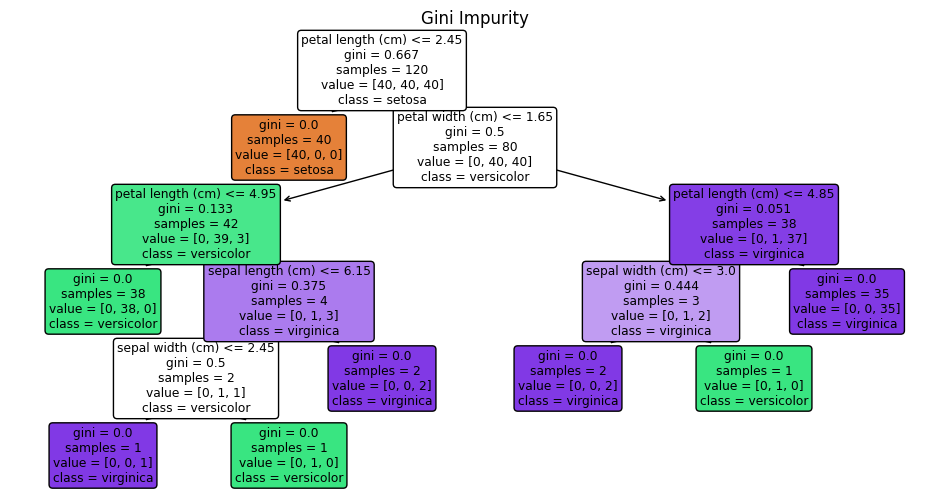


Model: Entropy (Information Gain)
Accuracy: 93.33 %
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



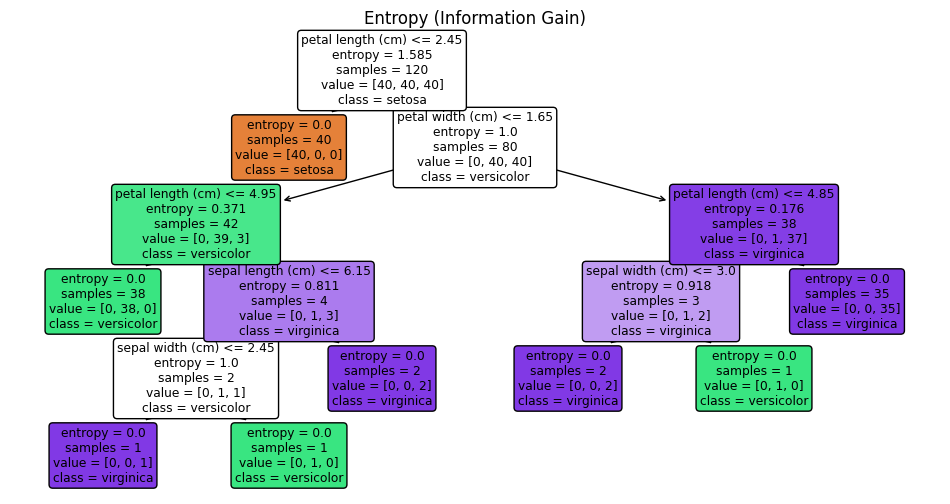

In [ ]:
#Qn-1b

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt

iris = load_iris()
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

models = {
    "Gini Impurity": DecisionTreeClassifier(
        criterion="gini", random_state=42
    ),
    "Entropy (Information Gain)": DecisionTreeClassifier(
        criterion="entropy", random_state=42
    )
}

for name, model in models.items():
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)

    print("\nModel:", name)
    print("Accuracy:", round(accuracy * 100, 2), "%")
    print(classification_report(
        y_test, y_pred,
        target_names=iris.target_names,
        zero_division=0
    ))

    plt.figure(figsize=(12, 6))
    plot_tree(
        model,
        feature_names=iris.feature_names,
        class_names=iris.target_names,
        filled=True,
        rounded=True
    )
    plt.title(name)
    plt.show()

Sigmoid(0): 0.5

Model: Ridge (L2)
Accuracy: 98.25 %
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114


Model: Lasso (L1)
Accuracy: 99.12 %
              precision    recall  f1-score   support

   malignant       1.00      0.98      0.99        42
      benign       0.99      1.00      0.99        72

    accuracy                           0.99       114
   macro avg       0.99      0.99      0.99       114
weighted avg       0.99      0.99      0.99       114



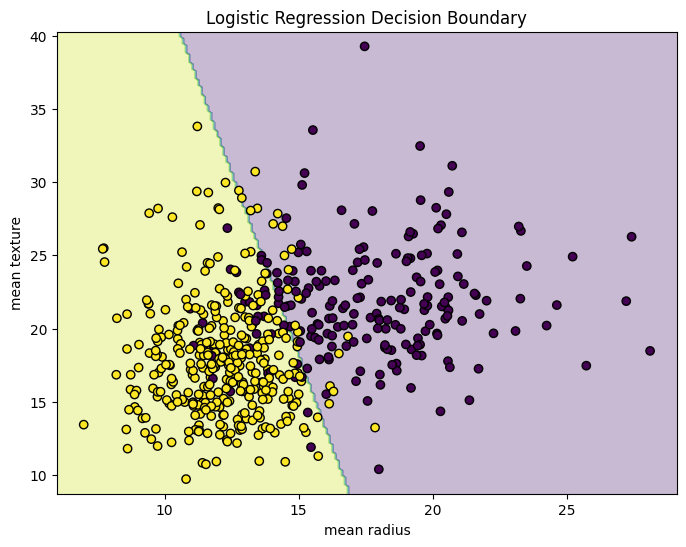

In [ ]:
#Qn-1c

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report

data = load_breast_cancer()
X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

print("Sigmoid(0):", sigmoid(0))

models = {
    "Ridge (L2)": make_pipeline(
        StandardScaler(),
        LogisticRegression(penalty="l2", C=1.0, max_iter=5000)
    ),
    "Lasso (L1)": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            penalty="l1", solver="liblinear",
            C=1.0, max_iter=5000
        )
    )
}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    print("\nModel:", name)
    print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
    print(classification_report(
        y_test, y_pred, target_names=data.target_names
    ))

X2 = X[:, :2]
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y, test_size=0.2, random_state=42, stratify=y
)

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=5000)
)
model.fit(X2_train, y2_train)

x_min, x_max = X2[:, 0].min() - 1, X2[:, 0].max() + 1
y_min, y_max = X2[:, 1].min() - 1, X2[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 200),
    np.linspace(y_min, y_max, 200)
)

grid = np.c_[xx.ravel(), yy.ravel()]
Z = model.predict(grid).reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.3)
plt.scatter(X2[:, 0], X2[:, 1], c=y, edgecolors="black")
plt.xlabel(data.feature_names[0])
plt.ylabel(data.feature_names[1])
plt.title("Logistic Regression Decision Boundary")
plt.show()

In [ ]:
#Qn-1d

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

iris = load_iris()
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred,
                            target_names=iris.target_names))

sample = [[5.1, 3.5, 1.4, 0.2]]
sample_scaled = scaler.transform(sample)
prediction = knn.predict(sample_scaled)

print("Predicted flower:", iris.target_names[prediction[0]])

Accuracy: 93.33 %

Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30

Predicted flower: setosa


In [ ]:
#Qn-1e

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

iris = load_iris()
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = GaussianNB()

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred, target_names=iris.target_names
))

sample = [[5.1, 3.5, 1.4, 0.2]]
prediction = model.predict(sample)

print("Predicted flower:", iris.target_names[prediction[0]])

Accuracy: 96.67 %

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

Predicted flower: setosa
